# GPTRec: sequential recommendations с трансформером

Учим GPT-like модель предсказывать следующий фильм в истории пользователя на датасете MovieLens-1M.

План:
1. Загружаем данные.
2. Собираем датасеты и даталоадеры.
3. Определяем модель: эмбеддинги items + GPT-2 + выходной слой.
4. Обучаем с PyTorch Lightning.
5. Строим рекомендации и считаем метрики на тесте.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pytorch_lightning as pl
import torch
from pytorch_lightning.callbacks import EarlyStopping, ModelCheckpoint
from pytorch_lightning.loggers import CSVLogger
from torch import nn
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader, Dataset
from transformers import GPT2Config, GPT2Model

pl.seed_everything(42)

Seed set to 42


42

## Данные

In [2]:
DATA_PATH = '/home/jovyan/shares/SR003.nfs2/recsys_data/split_data/'

In [3]:
train = pd.read_csv(os.path.join(DATA_PATH, 'train_Movielens.csv'))
train = train.sort_values(['user_id', 'timestamp'])
print(train.shape)
train.head()

(799689, 4)


,user_id,item_id,ratings,timestamp
0,634,1936,5,975767861
1,634,446,5,975767861
2,634,768,4,975767911
3,634,3105,4,975767911
4,634,1068,4,975768106


In [4]:
validation = pd.read_csv(os.path.join(DATA_PATH, 'validation_Movielens.csv'))
validation = validation.sort_values(['user_id', 'timestamp'])

test = pd.read_csv(os.path.join(DATA_PATH, 'test_Movielens.csv'))
test = test.sort_values(['user_id', 'timestamp'])

In [5]:
# item_id starts from 0, but 0 is used for padding, so shift all ids by 1
for df in [train, validation, test]:
    df['item_id'] += 1

# split test: last item of each user is the target, all previous items are model inputs
is_last = test.groupby('user_id').cumcount(ascending=False) == 0
test_inputs = test[~is_last]
test_targets = test[is_last]
print(test_inputs.shape, test_targets.shape)

(363850, 4) (1209, 4)


## Датасеты

In [6]:
class TrainDataset(Dataset):

    def __init__(self, df, max_length=128,
                 user_col='user_id', item_col='item_id', time_col='timestamp'):

        self.max_length = max_length
        self.user_col = user_col
        self.item_col = item_col
        self.time_col = time_col

        self.data = df.sort_values(time_col).groupby(user_col)[item_col].agg(list).to_dict()
        self.user_ids = list(self.data.keys())

    def __len__(self):

        return len(self.data)

    def __getitem__(self, idx):

        user_id = self.user_ids[idx]
        item_sequence = self.data[self.user_ids[idx]]

        if len(item_sequence) > self.max_length + 1:
            item_sequence = item_sequence[-self.max_length - 1:]

        input_ids = np.array(item_sequence[:-1])
        labels = np.array(item_sequence[1:])

        return {'user_id': user_id, 'input_ids': input_ids, 'labels': labels}

In [7]:
class PredictionDataset(TrainDataset):


    def __init__(self, df, max_length=128, validation_mode=False,
                 user_col='user_id', item_col='item_id',
                 time_col='timestamp'):

        super().__init__(df, max_length=max_length,
                         user_col=user_col, item_col=item_col, time_col=time_col)

        self.validation_mode = validation_mode

    def __getitem__(self, idx):

        user_id = self.user_ids[idx]
        item_sequence = self.data[user_id]

        if self.validation_mode:
            target = item_sequence[-1]
            input_ids = item_sequence[-self.max_length-1:-1]
            item_sequence = item_sequence[:-1]

            return {'input_ids': input_ids, 'user_id': user_id,
                    'full_history': item_sequence, 'target': target}
        else:
            input_ids = item_sequence[-self.max_length:]

            return {'input_ids': input_ids, 'user_id': user_id,
                    'full_history': item_sequence}

In [8]:
class PaddingCollateFn:

    def __init__(self, padding_value=0, labels_padding_value=-100):

        self.padding_value = padding_value
        self.labels_padding_value = labels_padding_value

    def __call__(self, batch):

        collated_batch = {}

        for key in batch[0].keys():

            if np.isscalar(batch[0][key]):
                collated_batch[key] = torch.tensor([example[key] for example in batch])
                continue

            if key == 'labels':
                padding_value = self.labels_padding_value
            else:
                padding_value = self.padding_value

            values = [torch.tensor(example[key]) for example in batch]
            collated_batch[key] = pad_sequence(values, batch_first=True,
                                                padding_value=padding_value)

        if 'input_ids' in collated_batch:
            attention_mask = collated_batch['input_ids'] != self.padding_value
            collated_batch['attention_mask'] = attention_mask.to(dtype=torch.float32)

        return collated_batch

In [9]:
MAX_LENGTH = 64
BATCH_SIZE = 128
EVAL_BATCH_SIZE = 128
NUM_WORKERS = 4

train_dataset = TrainDataset(train, max_length=MAX_LENGTH)
eval_dataset = PredictionDataset(validation, max_length=MAX_LENGTH, validation_mode=True)
test_dataset = PredictionDataset(test_inputs, max_length=MAX_LENGTH, validation_mode=False)

collate_fn = PaddingCollateFn()

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=NUM_WORKERS,
    collate_fn=PaddingCollateFn())
eval_loader = DataLoader(
    eval_dataset, batch_size=EVAL_BATCH_SIZE,
    shuffle=False, num_workers=NUM_WORKERS,
    collate_fn=PaddingCollateFn())
test_loader = DataLoader(
    test_dataset, batch_size=EVAL_BATCH_SIZE,
    shuffle=False, num_workers=NUM_WORKERS,
    collate_fn=PaddingCollateFn())

In [10]:
batch = next(iter(train_loader))
{key: value.shape for key, value in batch.items()}

{'user_id': torch.Size([128]),
 'input_ids': torch.Size([128, 64]),
 'labels': torch.Size([128, 64]),
 'attention_mask': torch.Size([128, 64])}

In [11]:
batch

{'user_id': tensor([5528, 3828, 5211, 1855,  956, 5475, 5098, 3570, 4155, 5600, 4244, 2993,
         1710, 4268, 5155, 3501,  857, 5036, 5544,  985, 5746, 5423, 2648, 5999,
         4112, 2723, 3655, 3374, 5335, 1597, 5416, 5337, 2268, 1043, 1141, 3027,
         3372, 4718, 2523, 3528, 1918, 4596, 3392, 4240, 2355,  901, 1675, 5125,
         1853, 1569, 2046, 1837, 3253, 3788, 2592, 5926, 4251, 5735, 1550, 2499,
         1336, 3343, 4633, 5720, 4222, 5991, 4220,  962, 4766, 3889, 2940, 3159,
         1801, 4822, 1265, 3668, 3745, 2376, 3897, 4821, 3132, 2840, 1172, 2291,
         5535, 4771, 4922, 1644, 1459, 5293, 1970, 1494, 3988, 5503, 1241, 4053,
         5942, 2049, 1806,  681, 4459, 4741, 5192, 1626,  802, 4862,  818, 5554,
         2771, 2026, 4883, 1301, 4363, 2468, 2740, 4611, 1719, 5521, 3587, 5000,
          838, 3131, 4140, 2690,  758, 2825, 3207, 5511]),
 'input_ids': tensor([[ 504, 1588, 2372,  ...,    0,    0,    0],
         [1051, 2951, 1852,  ..., 3363, 3367, 3230],
 

## Модель

In [12]:
class GPTRec(nn.Module):

    def __init__(self, gpt_config, vocab_size=None, tie_weights=True,
                 padding_idx=0, init_std=0.02):

        super().__init__()

        self.gpt_config = gpt_config
        self.vocab_size = vocab_size
        self.tie_weights = tie_weights
        self.padding_idx = padding_idx
        self.init_std = init_std

        self.embed_layer = nn.Embedding(num_embeddings=vocab_size,
                                        embedding_dim=gpt_config['n_embd'],
                                        padding_idx=padding_idx)
        self.transformer_model = GPT2Model(GPT2Config(**gpt_config))

        self.head = nn.Linear(gpt_config['n_embd'], self.vocab_size, bias=False)
        if self.tie_weights:
            self.head.weight = self.embed_layer.weight

        self.init_weights()

    def init_weights(self):

        self.embed_layer.weight.data.normal_(mean=0.0, std=self.init_std)
        if self.padding_idx is not None:
            self.embed_layer.weight.data[self.padding_idx].zero_()

    def forward(self, input_ids, attention_mask):

        embeds = self.embed_layer(input_ids)
        transformer_outputs = self.transformer_model(
            inputs_embeds=embeds, attention_mask=attention_mask)
        outputs = transformer_outputs.last_hidden_state
        outputs = self.head(outputs)

        return outputs


In [13]:
GPT_CONFIG = {
    'vocab_size': 2,
    'n_positions': MAX_LENGTH,
    'n_embd': 64,
    'n_layer': 2,
    'n_head': 1,
}

vocab_size = train.item_id.max() + 1
model = GPTRec(GPT_CONFIG, vocab_size)

In [14]:
outputs = model(batch['input_ids'], batch['attention_mask'])
outputs.shape

torch.Size([128, 64, 3417])

In [15]:
loss_fct = nn.CrossEntropyLoss()
loss = loss_fct(outputs.view(-1, outputs.size(-1)), batch['labels'].view(-1))
loss

tensor(8.1492, grad_fn=<NllLossBackward0>)

## Метрики


In [16]:
def compute_metrics(preds, targets):
    """preds: [n_users, k] top-k items, targets: [n_users] true items."""
    hits = preds == targets[:, None]
    ranks = hits.float().argmax(dim=1) + 1
    found = hits.any(dim=1).float()
    return {
        'ndcg': (found / torch.log2(ranks + 1.0)).mean().item(),
        'hit_rate': found.mean().item(),
        'mrr': (found / ranks).mean().item(),
    }

## Lightning-модуль

In [17]:
class SeqRec(pl.LightningModule):

    def __init__(self, model, lr=1e-3, top_k=10, filter_seen=True):

        super().__init__()

        self.model = model
        self.lr = lr
        self.top_k = top_k
        self.filter_seen = filter_seen

    def configure_optimizers(self):

        return torch.optim.Adam(self.parameters(), lr=self.lr)

    def training_step(self, batch, batch_idx):

        outputs = self.model(batch['input_ids'], batch['attention_mask'])
        loss = nn.functional.cross_entropy(outputs.view(-1, outputs.size(-1)), batch['labels'].view(-1))
        self.log('train_loss', loss, prog_bar=True)

        return loss

    def validation_step(self, batch, batch_idx):

        preds = self.predict_step(batch, batch_idx)['preds']
        metrics = compute_metrics(preds, batch['target'])

        self.log_dict({f'val_{name}': value for name, value in metrics.items()},
                      prog_bar=True, batch_size=len(preds))

    def predict_step(self, batch, batch_idx):

        outputs = self.model(batch['input_ids'], batch['attention_mask'])

        last_idx = batch['attention_mask'].sum(dim=1).long() - 1
        logits = outputs[torch.arange(len(last_idx)), last_idx]  # [batch_size, vocab_size]

        if self.filter_seen:
            # set -inf scores for already seen items (and for padding index 0)
            logits = logits.scatter(1, batch['full_history'], -torch.inf)

        scores, preds = logits.topk(self.top_k, dim=1)

        return {'user_id': batch['user_id'], 'preds': preds, 'scores': scores}

## Обучение

In [18]:
seqrec_module = SeqRec(model, lr=1e-3, filter_seen=True)

checkpoint = ModelCheckpoint(monitor='val_ndcg', mode='max', save_weights_only=True)
early_stopping = EarlyStopping(monitor='val_ndcg', mode='max', patience=10)

trainer = pl.Trainer(max_epochs=50, accelerator='auto', devices=1,
                     callbacks=[checkpoint, early_stopping], logger=CSVLogger('logs'))

trainer.fit(seqrec_module, train_dataloaders=train_loader, val_dataloaders=eval_loader)

GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


You are using a CUDA device ('NVIDIA A100-SXM4-80GB') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [2]


┏━━━┳━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type   ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model │ GPTRec │  323 K │ train │     0 │
└───┴───────┴────────┴────────┴───────┴───────┘

Trainable params: 323 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 323 K                                                                                                
Total estimated model params size (MB): 1.292                                                                      
Modules in train mode: 35                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/home/jovyan/.local/lib/python3.11/site-packages/pytorch_lightning/loops/fit_loop.py:321: The number of training 
batches (43) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for 
log_every_n_steps if you want to see logs for the training epoch.

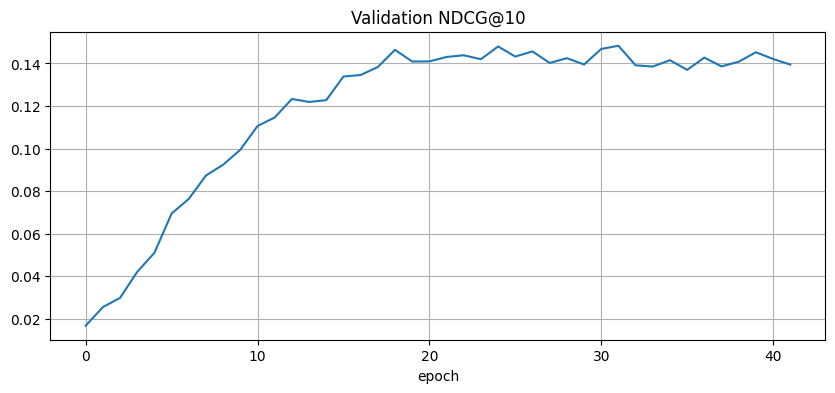

In [19]:
history = pd.read_csv(os.path.join(trainer.logger.log_dir, 'metrics.csv'))
history = history.dropna(subset=['val_ndcg']).set_index('epoch')

history['val_ndcg'].plot(figsize=(10, 4), title='Validation NDCG@10', grid=True)
plt.show()

## Рекомендации и метрики на тесте

In [20]:
preds = trainer.predict(seqrec_module, dataloaders=test_loader, ckpt_path='best')

user_ids = torch.cat([p['user_id'] for p in preds]).cpu()
items = torch.cat([p['preds'] for p in preds]).cpu()
scores = torch.cat([p['scores'] for p in preds]).cpu()

recs = pd.DataFrame({
    'user_id': user_ids.repeat_interleave(items.shape[1]).numpy(),
    'item_id': items.flatten().numpy(),
    'score': scores.flatten().numpy(),
})
recs.head(10)

Restoring states from the checkpoint path at logs/lightning_logs/version_0/checkpoints/epoch=31-step=1376.ckpt


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [2]


Loaded model weights from the checkpoint at logs/lightning_logs/version_0/checkpoints/epoch=31-step=1376.ckpt


Output()

,user_id,item_id,score
0,0,341,7.764176
1,0,1757,7.190062
2,0,2031,7.075533
3,0,570,6.944414
4,0,1424,6.925471
5,0,1753,6.818049
6,0,872,6.776317
7,0,1749,6.763625
8,0,1764,6.663487
9,0,1804,6.644924


In [21]:
targets = torch.tensor(test_targets.set_index('user_id').loc[user_ids.numpy(), 'item_id'].values)
pd.Series(compute_metrics(items, targets))

ndcg        0.084928
hit_rate    0.147229
mrr         0.066129
dtype: float64